# Post5G - TDD Patterns

## Prerequisites

Before starting, make sure you:

- Have completed the [Simple Scenario](./simple.ipynb) and [Adding component](./add_components.ipynb) tutorials.
- Have a basic understanding of Python.
- Have a good understanding of the 5G architecture.
- Have a good undesrtanding of Time Division Duplex (TDD)

## Experiment for this scenario

Thanks to the [Adding component scenario](./add_components.ipynb) we have a
running 5G network. In this scenario, we will modify the TDD configuration of
the gNB named `gnb2` and measure the impact of the change on the performances.

The figure below is a reminder of the 5G network we are considering.

![Add component topology](./figures/add_component.png)

## Recover metamodel and deployment model of an existing deployment

We assume that a 5G network is already deployed and running and that its
metamodel and deployment model are saved in files
`state/add_components/metamodel.ues.yaml` and
`state/add_components/deployment_model.ues.yaml`. We car retrieve the metalmodel
and deployment model from these files.


In [1]:
from metamodel.models.metamodel import MetaModel
from orchestrator.models.deployment import DeploymentModel

metamodel = MetaModel.from_yaml_file('state/add_components/metamodel.ues.yaml')
deployment_model = DeploymentModel.from_yaml_file('state/add_components/deployment_model.ues.yaml')

Let's first determine the current TDD pattern on `gnb2`. This information is stored in the `radioConfiguration.tddConfiguration` attribute of the gNB configuration in the metamodel.


In [2]:
tdd = metamodel.ran.components["gnb2"].config.radioConfiguration.tddConfiguration
print (tdd.to_yaml(exclude_defaults=False))

periodicityMilliseconds: 5.0
nrofDownlinkSlots: 7
nrofDownlinkSymbols: 6
nrofUplinkSlots: 2
nrofUplinkSymbols: 4



We can also represent this setting in a more user friendly way.

Current TDD pattern is: DDDDDDDSUU


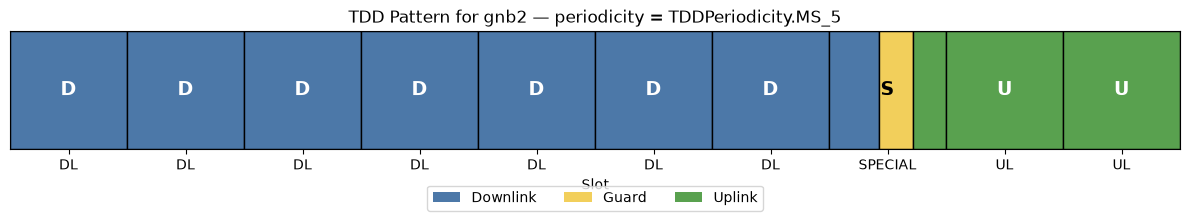

In [3]:
from tdd import generate_tdd_pattern, plot_tdd_pattern
pattern = generate_tdd_pattern(tdd)
print (f"Current TDD pattern is: {pattern}")
plot_tdd_pattern(gnb="gnb2", tdd=tdd)

## Measure delay and througput

We can now measure the delay and throughput at the UE.

To remove the impact of the data network (N6 interface), we will measure these
metrics between the UE and the tunnel endpoint at the UPF. Its IP address is
`11.1.1.1` in our scenario.

In [4]:
PING_COUNT=60
IPERF_DURATION=60
ENDPOINT="11.1.1.1"

### Delay measurement

We measure the delay as the value obtained by a ping to the UPF. First we run
the ping command, then we can plot its evolution with time.

In [5]:
from orchestrator.deployment import UEManagement
ues = UEManagement(metamodel=metamodel, deployment_model=deployment_model)

command = ["ping", "-I", "oaitun_ue1", "-c", PING_COUNT, "-D", ENDPOINT]
ping = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"]

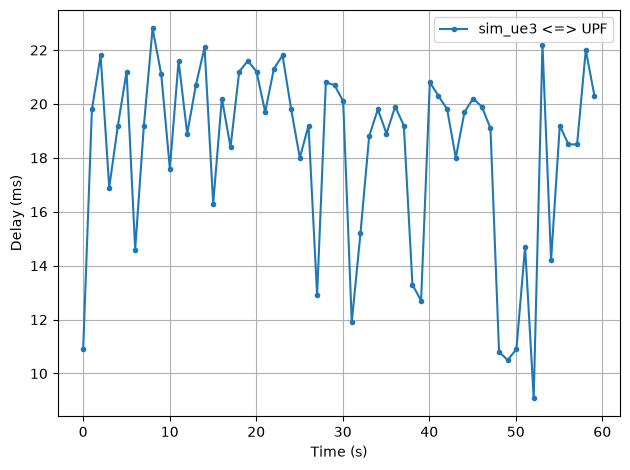

In [6]:
import re
def parse_ping(ping_output):
    pings = [
    (float(timestamp), float(delay))
    for timestamp, delay in re.findall(
        r'\[(\d+\.\d+)\].*time[=<]([\d.]+)\s*ms',
        ping_output
    )
    ]
    return pings

import matplotlib.pyplot as plt
def plot_ping(data, label, savefile=None):
    points = parse_ping(data)
    timestamps, delays = zip(*points)

    t0 = timestamps[0]
    elapsed = [t - t0 for t in timestamps]

    plt.plot(elapsed, delays, marker=".", label=label)

    plt.xlabel("Time (s)")
    plt.ylabel("Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    
    if savefile is not None:
        plt.savefig(savefile, dpi=300, bbox_inches="tight")
    plt.show()

plot_ping(data=ping, label="sim_ue3 <=> UPF")

### Througput measurement

We measure the troughput as the result of running TCP iPerf 3 between the UE and
the UPF.

To do it, we first need to start an `iperf3` daemon on the UPF then we can run
the `iperf31 client on the UE.

In [7]:
from orchestrator.deployment import CoreManagement
core = CoreManagement(metamodel=metamodel, deployment_model=deployment_model)

command = ["iperf3", "-s", "-D", "--logfile", "/iperf3.log"]
result = (await core.run_command(command=command, components=["upf"], quiet=True))["upf"]


In [8]:
command = ["bash", "-c", "'ip -4 addr show oaitun_ue1 | grep -oP \"(?<=inet )\\d+(\\.\\d+){3}\"'"]
sim_ue3_ip = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"].rstrip()
print (f"IP address of sim_ue3 {sim_ue3_ip}")

command = ["iperf3", "-c", ENDPOINT, "-B", sim_ue3_ip, "-t" , IPERF_DURATION, "-J", "--bidir"]
result = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"]

IP address of sim_ue3 11.1.1.4


In [9]:
import json
def plot_throughput(iperf_json: str, title: str = "Bi-directional Throughput", savefile=None):
    data = json.loads(iperf_json)

    ul_time, ul_mbps = [], []
    dl_time, dl_mbps = [], []

    for interval in data["intervals"]:
        end_time = interval["sum"]["end"]

        # In --bidir mode, individual direction details sit inside interval["streams"]
        for stream in interval["streams"]:
            mbps = stream["bits_per_second"] / 1e6

            # Identify direction: stream 1 is local sender (Uplink), stream 2 is local receiver (Downlink)
            if stream.get("sender", False):
                ul_time.append(end_time)
                ul_mbps.append(mbps)
            else:
                dl_time.append(end_time)
                dl_mbps.append(mbps)

    # Plot the figure
    plt.figure(figsize=(10, 5))

    plt.plot(
        ul_time,
        ul_mbps,
        marker="o",
        color="b",
        linestyle="-",
        linewidth=2,
        label="Uplink (TX)",
    )
    plt.plot(
        dl_time,
        dl_mbps,
        marker="s",
        color="r",
        linestyle="--",
        linewidth=2,
        label="Downlink (RX)",
    )

    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Bitrate (Mbps)")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.ylim(bottom=0)
    plt.legend()

    if savefile is not None:
        plt.savefig(savefile, dpi=300, bbox_inches="tight")
        plt.show()
    plt.show()

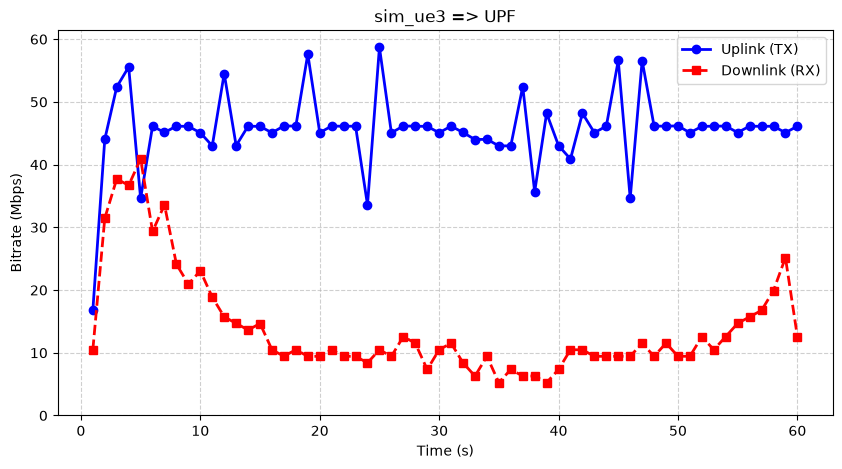

In [10]:
plot_throughput(result, " sim_ue3 => UPF ")


## Change TTD pattern

We now change the TDD pattern to have 5 downlink slots and 4 uplink slots, also
described as `DDDDDSUUUU`.

Unfortunately OAI does not support radio configuration changes on the fly. The
solution is then to remove the gNB from the RAN and create a new instance with
the new configuration with the help of a `RANManagement` manager.  It also
implies to remove the UE and relaunch it after the gNB is restarted as we use a
simulated radio channel bounding UE and gNB instances.

In [12]:
from orchestrator.deployment import RANManagement, UEManagement
ues = UEManagement(metamodel=metamodel, deployment_model=deployment_model)
await ues.uninstall(components=["sim_ue3"])

ran = RANManagement(preceding=ue)
await ran.uninstall(components=["gnb2"])


PLAY [node-core] ***************************************************************

TASK [helm/uninstall : Uninstall 'oai-sim-ue3' Helm chart] *********************
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
[WARNING]: Deprecation warnings can be disabled by setting `deprecation_warnings=False` in ansible.cfg.
[DEPRECATION WARNING]: The 'status.values' return value is deprecated and will be removed in version 8.0.0. Use 'status.release_values' instead. This feature will be removed from collection 'kubernetes.core' version 8.0.0.
changed: [node-core]

TASK [helm/uninstall : Wait for 'oai-sim-ue3' pod to be deleted] ***************
ok: [node-core]

TASK [helm/uninstall : Clean up Helm build directory for 'oai-sim-u

We add the gNB in the same way as before, except that we augmented its metamodel
with the TDD Configuration of our will.

In [13]:

import yaml
merged_model = yaml.safe_load(
"""
type: gnb
implementation: oai
config:
  radioConfiguration:
    tddConfiguration:
      periodicityMilliseconds: 5.0
      nrofDownlinkSlots: 5
      nrofDownlinkSymbols: 6
      nrofUplinkSlots: 4
      nrofUplinkSymbols: 4
""")

ran.add_component(name="gnb2", merged=merged_model)
await ran.deploy()



PLAY [node-core] ***************************************************************

PLAY [node-core] ***************************************************************

TASK [helm/prepare : Create Helm build directory for 'ueransim-gnb' chart] *****

TASK [helm/prepare : Create Helm build directory for 'oai-gnb2' chart] *********
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [node-core]

TASK [helm/prepare : Copy local 'oai-gnb' Helm chart directory for 'oai-gnb2'] ***
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.2

Let's check that the Manager uses the proper TDD configuration. Note that we
use the metamodel of the manager directly.

periodicityMilliseconds: 5.0
nrofDownlinkSlots: 5
nrofDownlinkSymbols: 6
nrofUplinkSlots: 4
nrofUplinkSymbols: 4

Current TDD pattern is: DDDDDSUUUU


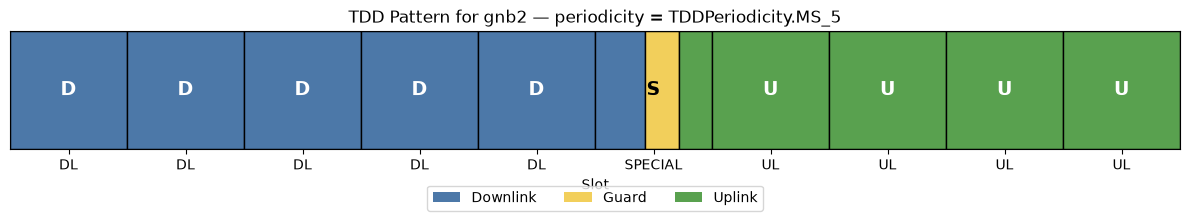

In [15]:
tdd = ran.metamodel.ran.components["gnb2"].config.radioConfiguration.tddConfiguration
print (tdd.to_yaml(exclude_defaults=False))
pattern = generate_tdd_pattern(tdd)
print (f"Current TDD pattern is: {pattern}")
plot_tdd_pattern(gnb="gnb2", tdd=tdd)

We can now re-deploy the UE.

In [16]:
ues = UEManagement(preceding=ran)
await ues.deploy(components=["sim_ue3"])


PLAY [node-core] ***************************************************************

TASK [helm/prepare : Create Helm build directory for 'oai-sim-ue3' chart] ******
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [node-core]

TASK [helm/prepare : Copy local 'oai-containerized' Helm chart directory for 'oai-sim-ue3'] ***
ok: [node-core]

TASK [helm/prepare : Render 'oai-sim-ue3' Helm Chart.yaml file from Jinja template] ***
ok: [node-core]

TASK [helm/prepare : Render templated Helm files for 'oai-sim-ue3'] ************
ok: [node-core] => (item=values.yaml)
changed: [node-core] => (item=config.yaml)

PLAY RECAP *********************************************************************
node-core                  : ok=4  

The UE is now attached to the gNB and we can measure and represent the delay and throughput as we did earlier in this tutorial in order to compare the achieved performance over the radio link.

### Delay measurement

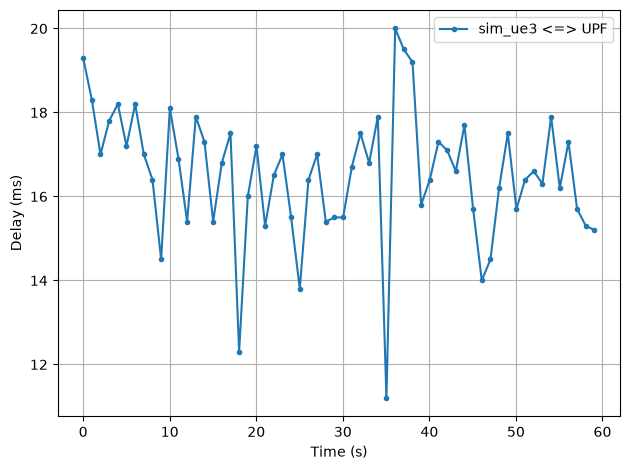

In [17]:
command = ["ping", "-I", "oaitun_ue1", "-c", PING_COUNT, "-D", ENDPOINT]
ping = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"]
plot_ping(data=ping, label="sim_ue3 <=> UPF")

### Throughput measurement


In [21]:
command = ["bash", "-c", "'ip -4 addr show oaitun_ue1 | grep -oP \"(?<=inet )\\d+(\\.\\d+){3}\"'"]
sim_ue3_ip = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"].rstrip()
print (f"IP address of sim_ue3 {sim_ue3_ip}")

command = ["iperf3", "-c", ENDPOINT, "-B", sim_ue3_ip, "-t" , IPERF_DURATION, "-J", "--bidir"]
result = (await ues.run_command(command=command, components=["sim_ue3"], quiet=True))["sim_ue3"]


IP address of sim_ue3 11.1.1.5


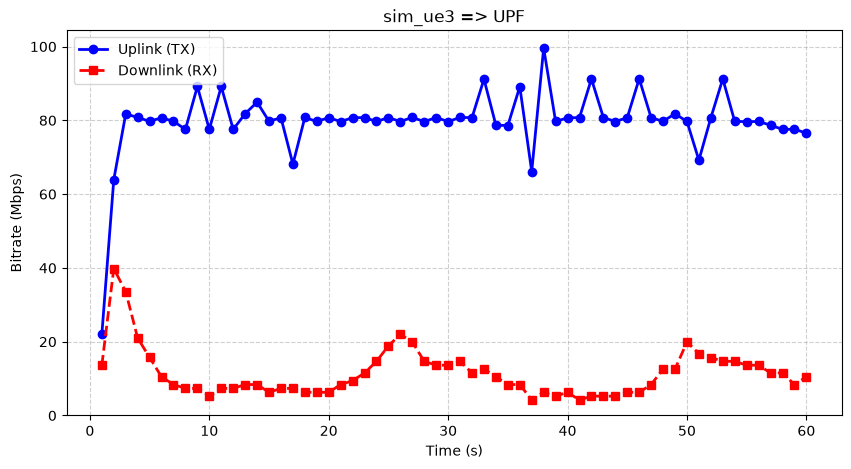

In [22]:
plot_throughput(result, " sim_ue3 => UPF ")

As usual let's archive our metamodel and deployment model.

In [23]:
from pathlib import Path
DIR="state/tdd"
Path(DIR).mkdir(parents=True, exist_ok=True)

ues.metamodel.to_yaml_file(f"{DIR}/metamodel.ues.yaml")
ues.deployment_model.to_yaml_file(f"{DIR}/deployment_model.ues.yaml")